# XGBoost user-item cross terms — validation notebook

Self-contained ablation extending the pointwise XGBoost recommender with user-item
**cross terms** (multiplicative interaction features) and a shrunk per-(user, genre)
affinity feature. The binary threshold `T` is swept over `{2, 3, 4, 5}`; at each `T`
we train XGBoost (`binary:logistic`, seed 42, `max_depth=6`), rank by predicted
P(positive), and evaluate `precision@10` / `recall@10` / `NDCG@10` against the
popularity baseline and the prior no-cross-terms run.

The only shared import is the raw data loader `movielens.data`. All model, feature,
training, and evaluation logic is inline.

In [1]:
%matplotlib inline
import hashlib
import os
import subprocess
import sys
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt


def repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "src" / "movielens").is_dir() and (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("repository root not found")


ROOT = repo_root()
sys.path.insert(0, str(ROOT / "src"))

import mlflow
import numpy as np
import pandas as pd
from xgboost import XGBClassifier

from movielens.data import RAW_DIR, extract_release_year, load_movies, load_ratings, load_users

SEED = 42
K = 10
EXPERIMENT = "xgboost"
REGISTRY_NAME = "xgboost-v1"
MLFLOW_URI = (ROOT / "mlflow" / "mlruns").as_uri()
THRESHOLDS = [2, 3, 4, 5]
PRIOR_RUN_ID = "fdab1c40799f460db34a2ec60e8c9774"
PRIOR_PRECISION = 0.027137
PRIOR_RECALL = 0.006287

os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

plt.rcParams["figure.figsize"] = (8, 3.5)

2026/10/17 17:18:43 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Franco\.pyenv\pyenv-win\versions\3.12.10\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## Model / feature / evaluation helpers

All logic inline. Base 47 tabular features; new 18 standalone `user_genre_affinity[g]`
columns; new 24 cross terms. Total 89 features. No scaling.

In [2]:
@dataclass
class Lookups:
    feature_names: list[str]
    user_index: dict[int, int]
    movie_index: dict[int, int]
    movie_ids: np.ndarray
    user_age: np.ndarray
    user_gender: np.ndarray
    user_occupation: np.ndarray
    movie_genres: np.ndarray
    movie_year: np.ndarray
    user_mean: np.ndarray
    item_mean: np.ndarray
    user_count: np.ndarray
    item_count: np.ndarray
    user_affinity: np.ndarray


def build_dataset():
    ratings = load_ratings()
    movies = load_movies()
    users = load_users()
    return ratings, movies, users


def chronological_split(ratings, train_frac=0.8, val_frac=0.1):
    df = ratings.sort_values(
        ["timestamp", "user_id", "movie_id"], kind="stable"
    ).reset_index(drop=True)
    n = len(df)
    train_end = int(train_frac * n)
    val_end = int((train_frac + val_frac) * n)
    return df.iloc[:train_end], df.iloc[train_end:val_end], df.iloc[val_end:]


def build_lookups(movies, users, train_full):
    genre_list = sorted(movies["genres"].str.split("|").explode().unique())
    occupation_list = sorted(users["occupation"].unique())
    gender_list = sorted(users["gender"].unique())

    user_ids = np.sort(users["user_id"].to_numpy())
    movie_ids = np.sort(movies["movie_id"].to_numpy())
    user_index = {int(u): i for i, u in enumerate(user_ids)}
    movie_index = {int(m): i for i, m in enumerate(movie_ids)}

    user_df = users.set_index("user_id").loc[user_ids]
    user_age = user_df["age"].to_numpy(dtype=np.float32)
    user_gender = pd.get_dummies(user_df["gender"]).reindex(
        columns=gender_list, fill_value=0
    ).to_numpy(dtype=np.float32)
    user_occupation = pd.get_dummies(user_df["occupation"]).reindex(
        columns=occupation_list, fill_value=0
    ).to_numpy(dtype=np.float32)

    movie_df = movies.set_index("movie_id").loc[movie_ids]
    movie_genres = pd.get_dummies(
        movie_df["genres"].str.split("|").explode()
    ).groupby(level=0).max().reindex(index=movie_ids, columns=genre_list, fill_value=0)
    movie_genres = movie_genres.to_numpy(dtype=np.float32)
    year = extract_release_year(movie_df["title"]).to_numpy(dtype=np.float32)
    year = np.nan_to_num(year, nan=-1.0)

    global_mean = float(train_full["rating"].mean())

    user_stats = train_full.groupby("user_id")["rating"].agg(["mean", "count"])
    item_stats = train_full.groupby("movie_id")["rating"].agg(["mean", "count"])

    user_mean = np.full(len(user_ids), global_mean, dtype=np.float32)
    user_count = np.zeros(len(user_ids), dtype=np.float32)
    for u, i in user_index.items():
        if u in user_stats.index:
            user_mean[i] = user_stats.at[u, "mean"]
            user_count[i] = user_stats.at[u, "count"]

    item_mean = np.full(len(movie_ids), global_mean, dtype=np.float32)
    item_count = np.zeros(len(movie_ids), dtype=np.float32)
    for m, i in movie_index.items():
        if m in item_stats.index:
            item_mean[i] = item_stats.at[m, "mean"]
            item_count[i] = item_stats.at[m, "count"]

    train_user_idx = train_full["user_id"].map(user_index).to_numpy(dtype=np.int64)
    train_movie_idx = train_full["movie_id"].map(movie_index).to_numpy(dtype=np.int64)
    train_rating = train_full["rating"].to_numpy(dtype=np.float32)
    centered = train_rating - global_mean
    genre_mask_per_rating = movie_genres[train_movie_idx]
    n_users = len(user_ids)
    n_genres = len(genre_list)
    sum_mat = np.zeros((n_users, n_genres), dtype=np.float32)
    count_mat = np.zeros((n_users, n_genres), dtype=np.float32)
    np.add.at(sum_mat, train_user_idx, centered[:, None] * genre_mask_per_rating)
    np.add.at(count_mat, train_user_idx, genre_mask_per_rating.astype(np.float32))
    user_affinity = sum_mat / (count_mat + 5.0)

    feature_names = (
        ["age"]
        + [f"gender_{g}" for g in gender_list]
        + [f"occupation_{o}" for o in occupation_list]
        + [f"genre_{g}" for g in genre_list]
        + [
            "release_year",
            "user_mean_rating",
            "item_mean_rating",
            "user_rating_count",
            "item_rating_count",
        ]
        + [f"user_genre_affinity_{g}" for g in genre_list]
        + ["um_x_im", "um_x_ic", "uc_x_im", "uc_x_ic", "age_x_year", "genre_affinity_score"]
        + [f"aff_x_genre_{g}" for g in genre_list]
    )

    return Lookups(
        feature_names=feature_names,
        user_index=user_index,
        movie_index=movie_index,
        movie_ids=movie_ids,
        user_age=user_age,
        user_gender=user_gender,
        user_occupation=user_occupation,
        movie_genres=movie_genres,
        movie_year=year,
        user_mean=user_mean,
        item_mean=item_mean,
        user_count=user_count,
        item_count=item_count,
        user_affinity=user_affinity,
    )


def build_features(user_ids, movie_ids, lookups):
    ui = pd.Series(user_ids).map(lookups.user_index).to_numpy(dtype=np.int64)
    mi = pd.Series(movie_ids).map(lookups.movie_index).to_numpy(dtype=np.int64)

    affinity = lookups.user_affinity[ui]
    genres = lookups.movie_genres[mi]
    um = lookups.user_mean[ui].reshape(-1, 1)
    im = lookups.item_mean[mi].reshape(-1, 1)
    uc = lookups.user_count[ui].reshape(-1, 1)
    ic = lookups.item_count[mi].reshape(-1, 1)

    base = np.hstack(
        [
            lookups.user_age[ui].reshape(-1, 1),
            lookups.user_gender[ui],
            lookups.user_occupation[ui],
            genres,
            lookups.movie_year[mi].reshape(-1, 1),
            um,
            im,
            uc,
            ic,
        ]
    )

    affinity_score = (affinity * genres).sum(axis=1, keepdims=True)
    cross = np.hstack(
        [
            um * im,
            um * ic,
            uc * im,
            uc * ic,
            lookups.user_age[ui].reshape(-1, 1) * lookups.movie_year[mi].reshape(-1, 1),
            affinity_score,
            affinity * genres,
        ]
    )

    return np.hstack([base, affinity, cross]).astype(np.float32)


def score_candidates(model, test_users, lookups, train_rated, batch_size=1000):
    n_movies = len(lookups.movie_ids)
    movie_arr = lookups.movie_ids
    recs = {}

    for start in range(0, len(test_users), batch_size):
        batch = test_users[start : start + batch_size]
        n_u = len(batch)
        seen = np.zeros((n_u, n_movies), dtype=bool)
        for i, u in enumerate(batch):
            for m in train_rated.get(u, set()):
                j = lookups.movie_index.get(m)
                if j is not None:
                    seen[i, j] = True

        counts = (~seen).sum(axis=1)
        total = int(counts.sum())
        uid_all = np.empty(total, dtype=np.int64)
        mid_all = np.empty(total, dtype=np.int64)
        pos = 0
        for i in range(n_u):
            cols = np.flatnonzero(~seen[i])
            c = int(cols.size)
            uid_all[pos : pos + c] = batch[i]
            mid_all[pos : pos + c] = movie_arr[cols]
            pos += c

        probs = model.predict_proba(build_features(uid_all, mid_all, lookups))[:, 1]

        pos = 0
        for i, u in enumerate(batch):
            c = int(counts[i])
            if c == 0:
                recs[u] = []
                continue
            sub = probs[pos : pos + c]
            mid = mid_all[pos : pos + c]
            order = np.argsort(-sub, kind="stable")
            recs[u] = mid[order].tolist()
            pos += c

    return recs


def popularity_recommendations(test_users, train_rated, train_full, k=K):
    pop_rank = (
        train_full.groupby("movie_id").size().sort_values(ascending=False).index.to_numpy()
    )
    recs = []
    for u in test_users:
        rated = train_rated.get(u, set())
        top = [int(m) for m in pop_rank if m not in rated][:k]
        recs.append(top)
    return recs


def precision_at_k(relevant, recommended, k=K):
    scores = []
    for rel, rec in zip(relevant, recommended):
        top = set(rec[:k])
        scores.append(len(top & rel) / k)
    return float(np.mean(scores)) if scores else 0.0


def recall_at_k(relevant, recommended, k=K):
    scores = []
    for rel, rec in zip(relevant, recommended):
        top = set(rec[:k])
        scores.append(len(top & rel) / len(rel) if rel else 0.0)
    return float(np.mean(scores)) if scores else 0.0


def ndcg_at_k(relevant, recommended, k=K):
    scores = []
    for rel, rec in zip(relevant, recommended):
        top = rec[:k]
        dcg = 0.0
        for i, m in enumerate(top):
            if m in rel:
                dcg += 1.0 / np.log2(i + 2)
        ideal = min(k, len(rel))
        idcg = sum(1.0 / np.log2(i + 2) for i in range(ideal))
        scores.append(dcg / idcg if idcg > 0 else 0.0)
    return float(np.mean(scores)) if scores else 0.0


def data_version_hash():
    digest = hashlib.sha1((RAW_DIR / "ratings.dat").read_bytes()).hexdigest()
    return digest[:12]


def git_sha():
    out = subprocess.run(
        ["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True
    )
    return out.stdout.strip()

## 1. EDA

Rating distribution and per-threshold class balance. All ratings 1-5 are retained;
for a threshold `T` the positive class is `rating >= T`.

n_users: 6040
n_movies: 3706
n_ratings (all 1-5): 1000209
sparsity (observed / users x movies): 0.0447



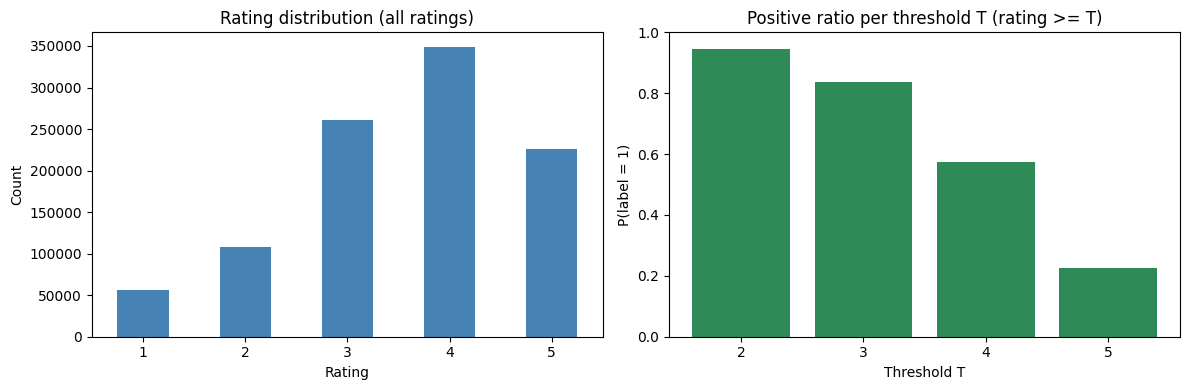

T=2: positives=944,035 (94.38%)
T=3: positives=836,478 (83.63%)
T=4: positives=575,281 (57.52%)
T=5: positives=226,310 (22.63%)


In [3]:
ratings, movies, users = build_dataset()

n_ratings = len(ratings)
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
sparsity = n_ratings / (n_users * n_movies)

print("n_users:", n_users)
print("n_movies:", n_movies)
print("n_ratings (all 1-5):", n_ratings)
print("sparsity (observed / users x movies):", round(sparsity, 4))
print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rating_counts = ratings["rating"].value_counts().sort_index()
rating_counts.plot(kind="bar", ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Rating distribution (all ratings)")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Count")

balances = {T: float((ratings["rating"] >= T).mean()) for T in THRESHOLDS}
axes[1].bar([str(T) for T in THRESHOLDS], [balances[T] for T in THRESHOLDS], color="seagreen")
axes[1].set_title("Positive ratio per threshold T (rating >= T)")
axes[1].set_xlabel("Threshold T")
axes[1].set_ylabel("P(label = 1)")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

for T in THRESHOLDS:
    print(f"T={T}: positives={(ratings['rating'] >= T).sum():,} ({balances[T]:.2%})")

## 2. Split + feature construction

Chronological 80/10/10 split (identical across thresholds — the sort key is timestamp
only). `build_lookups` computes the 47 base features plus the 18 standalone
`user_genre_affinity[g]` columns (shrunk mean-rating deviation, train-fold only) and
the 24 cross terms. Final feature count must be 89.

In [4]:
train, val, test = chronological_split(ratings)
train_end = int(train["timestamp"].max())
train_full = ratings[ratings["timestamp"] <= train_end]

lookups = build_lookups(movies, users, train_full)

X_train = build_features(train["user_id"].to_numpy(), train["movie_id"].to_numpy(), lookups)
X_val = build_features(val["user_id"].to_numpy(), val["movie_id"].to_numpy(), lookups)

print("split sizes train/val/test:", len(train), len(val), len(test))
print("n features:", len(lookups.feature_names))
print("train timestamp cutoff:", train_end)
print("base: 47, standalone affinity: 18, cross terms: 24 -> total:", len(lookups.feature_names))
assert len(lookups.feature_names) == 89, "feature count must be 89"
assert len(train) + len(val) + len(test) == n_ratings

split sizes train/val/test: 800167 100021 100021
n features: 89
train timestamp cutoff: 975768738
base: 47, standalone affinity: 18, cross terms: 24 -> total: 89


## 3. Training + evaluation sweep over thresholds

For each `T ∈ {2, 3, 4, 5}`: build labels `rating >= T`, train XGBoost
(`binary:logistic`, seed 42, `max_depth=6`, `scale_pos_weight = n_neg / n_pos`), rank
candidates by P(positive), and evaluate against the popularity baseline. The best
threshold is selected by `precision@10` (ties broken by higher `NDCG@10`).

In [5]:
test_users = sorted(test["user_id"].unique().tolist())
train_rated = train_full.groupby("user_id")["movie_id"].apply(set).to_dict()

results = {}
models_by_T = {}

for T in THRESHOLDS:
    y_train_T = (train["rating"] >= T).to_numpy(dtype=np.int64)
    y_val_T = (val["rating"] >= T).to_numpy(dtype=np.int64)
    n_pos = int((y_train_T == 1).sum())
    n_neg = int((y_train_T == 0).sum())
    spw = n_neg / n_pos if n_pos else 1.0

    params = dict(
        max_depth=6,
        n_estimators=100,
        learning_rate=0.1,
        scale_pos_weight=spw,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=SEED,
    )
    model = XGBClassifier(**params)
    model.fit(X_train, y_train_T, eval_set=[(X_val, y_val_T)], verbose=False)
    models_by_T[T] = model

    relevant_T = {
        u: set(test.loc[(test["user_id"] == u) & (test["rating"] >= T), "movie_id"])
        for u in test_users
    }
    eval_users_T = [u for u in test_users if relevant_T[u]]
    model_recs = score_candidates(model, eval_users_T, lookups, train_rated)
    pop_recs = popularity_recommendations(eval_users_T, train_rated, train_full)
    rel_list = [relevant_T[u] for u in eval_users_T]
    model_rec_list = [model_recs[u] for u in eval_users_T]

    results[T] = {
        "scale_pos_weight": spw,
        "n_pos": n_pos,
        "n_neg": n_neg,
        "n_eval_users": len(eval_users_T),
        "precision@10": precision_at_k(rel_list, model_rec_list, K),
        "recall@10": recall_at_k(rel_list, model_rec_list, K),
        "ndcg@10": ndcg_at_k(rel_list, model_rec_list, K),
        "baseline_precision@10": precision_at_k(rel_list, pop_recs, K),
        "baseline_recall@10": recall_at_k(rel_list, pop_recs, K),
        "baseline_ndcg@10": ndcg_at_k(rel_list, pop_recs, K),
    }
    print(
        f"T={T}: scale_pos_weight={spw:.4f} eval_users={len(eval_users_T)} "
        f"precision@10={results[T]['precision@10']:.6f} "
        f"recall@10={results[T]['recall@10']:.6f} "
        f"ndcg@10={results[T]['ndcg@10']:.6f}"
    )

best_T = max(THRESHOLDS, key=lambda T: (results[T]["precision@10"], results[T]["ndcg@10"]))
print("best threshold:", best_T)

T=2: scale_pos_weight=0.0601 eval_users=1208 precision@10=0.067550 recall@10=0.013378 ndcg@10=0.071991


T=3: scale_pos_weight=0.1939 eval_users=1205 precision@10=0.062822 recall@10=0.013159 ndcg@10=0.069782


T=4: scale_pos_weight=0.7281 eval_users=1188 precision@10=0.055219 recall@10=0.015145 ndcg@10=0.057167


T=5: scale_pos_weight=3.3304 eval_users=1071 precision@10=0.031559 recall@10=0.024401 ndcg@10=0.039232
best threshold: 2


## 4. Feature importance (best threshold)

Mean gain per feature, highlighting whether the new cross/affinity terms are among
the top contributors.

top 25 features by gain (best threshold T=2):
                        feature     gain
                        um_x_im 0.405373
           genre_affinity_score 0.039100
               item_mean_rating 0.028663
                   genre_Action 0.015133
                genre_Adventure 0.014726
                 genre_Thriller 0.013833
                       gender_F 0.012986
               genre_Children's 0.012941
               user_mean_rating 0.012619
                    genre_Drama 0.011948
        aff_x_genre_Documentary 0.011295
                        uc_x_im 0.010860
                  occupation_11 0.010545
                        uc_x_ic 0.010532
  user_genre_affinity_Adventure 0.010254
            aff_x_genre_Musical 0.010147
                   release_year 0.009290
      user_genre_affinity_Crime 0.009206
     user_genre_affinity_Action 0.009052
            aff_x_genre_Western 0.009031
                   occupation_1 0.008914
              user_rating_count 0.008763
    user_ge

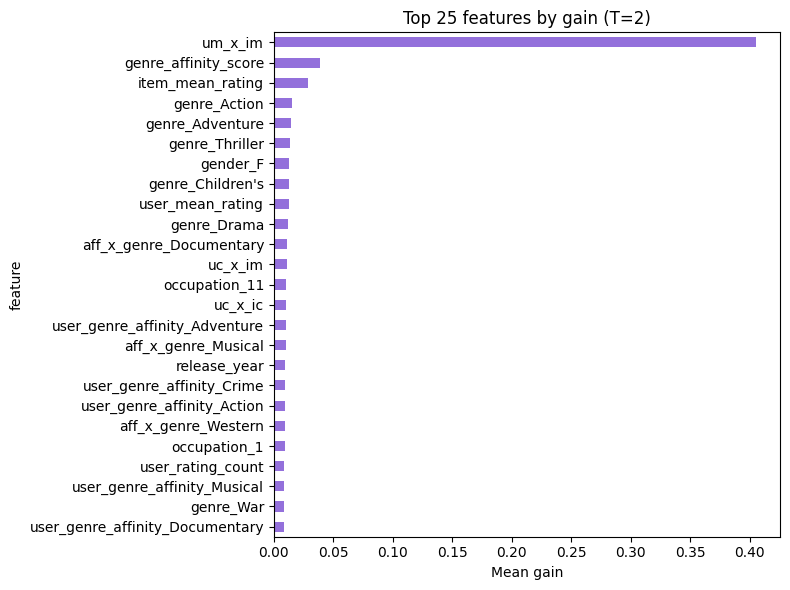

In [6]:
model = models_by_T[best_T]
importances = model.feature_importances_
imp_df = pd.DataFrame({"feature": lookups.feature_names, "gain": importances})
imp_df = imp_df.sort_values("gain", ascending=False).reset_index(drop=True)
print(f"top 25 features by gain (best threshold T={best_T}):")
print(imp_df.head(25).to_string(index=False))

top = imp_df.head(25).set_index("feature")["gain"]
top.plot(kind="barh", color="mediumpurple", figsize=(8, 6))
plt.gca().invert_yaxis()
plt.title(f"Top 25 features by gain (T={best_T})")
plt.xlabel("Mean gain")
plt.tight_layout()
plt.show()

## 5. Evaluation summary + comparison

Per-threshold model vs popularity baseline, the selected best threshold, and the
comparison against the prior no-cross-terms run `fdab1c40799f460db34a2ec60e8c9774`
(v7, which used the `T=3` framing).

In [7]:
rows = []
for T in THRESHOLDS:
    r = results[T]
    rows.append(
        {
            "T": T,
            "model_precision@10": r["precision@10"],
            "model_recall@10": r["recall@10"],
            "model_ndcg@10": r["ndcg@10"],
            "baseline_precision@10": r["baseline_precision@10"],
            "baseline_recall@10": r["baseline_recall@10"],
            "baseline_ndcg@10": r["baseline_ndcg@10"],
        }
    )
summary = pd.DataFrame(rows)
print("per-threshold model vs popularity baseline:")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print()
print("best threshold by precision@10 (ties -> higher NDCG@10):", best_T)
print()

r = results[best_T]
r3 = results[3]
print(
    f"best threshold T={best_T}: model precision@10={r['precision@10']:.6f} "
    f"vs baseline {r['baseline_precision@10']:.6f}"
)
print(
    f"prior run {PRIOR_RUN_ID} (v7, T=3 framing): "
    f"precision@10={PRIOR_PRECISION:.6f} recall@10={PRIOR_RECALL:.6f} (no NDCG@10 logged)"
)
print(
    f"this run at T=3 (same framing as prior): "
    f"precision@10={r3['precision@10']:.6f} recall@10={r3['recall@10']:.6f} "
    f"ndcg@10={r3['ndcg@10']:.6f}"
)

per-threshold model vs popularity baseline:
 T  model_precision@10  model_recall@10  model_ndcg@10  baseline_precision@10  baseline_recall@10  baseline_ndcg@10
 2            0.067550         0.013378       0.071991               0.212997            0.035990          0.224530
 3            0.062822         0.013159       0.069782               0.203154            0.038631          0.215432
 4            0.055219         0.015145       0.057167               0.170286            0.046312          0.182879
 5            0.031559         0.024401       0.039232               0.093557            0.072528          0.117692

best threshold by precision@10 (ties -> higher NDCG@10): 2

best threshold T=2: model precision@10=0.067550 vs baseline 0.212997
prior run fdab1c40799f460db34a2ec60e8c9774 (v7, T=3 framing): precision@10=0.027137 recall@10=0.006287 (no NDCG@10 logged)
this run at T=3 (same framing as prior): precision@10=0.062822 recall@10=0.013159 ndcg@10=0.069782


## 6. Log to MLflow (under the `test` alias)

Per-threshold metrics + params + the best-threshold model artifact, tagged
`code_version` / `data_version` / `intent=xgboost-user-item-cross-terms`, registered
under `xgboost-v1` with the `test` alias (no `Staging`/`Production`).

In [8]:
mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)
client = mlflow.tracking.MlflowClient()

best_model = models_by_T[best_T]

params_log = dict(
    max_depth=6,
    n_estimators=100,
    learning_rate=0.1,
    scale_pos_weight=results[best_T]["scale_pos_weight"],
    objective="binary:logistic",
    seed=SEED,
)
for T in THRESHOLDS:
    params_log[f"scale_pos_weight_T{T}"] = results[T]["scale_pos_weight"]

metric_log = {}
for T in THRESHOLDS:
    r = results[T]
    for k in [
        "precision@10",
        "recall@10",
        "ndcg@10",
        "baseline_precision@10",
        "baseline_recall@10",
        "baseline_ndcg@10",
    ]:
        metric_log[f"{k}_T{T}".replace("@", "_at_")] = r[k]
metric_log["best_threshold"] = best_T

with mlflow.start_run() as active_run:
    run_id = active_run.info.run_id
    mlflow.log_params(params_log)
    mlflow.log_metrics(metric_log)
    mlflow.set_tags(
        {
            "code_version": git_sha(),
            "data_version": data_version_hash(),
            "intent": "xgboost-user-item-cross-terms",
        }
    )
    info = mlflow.xgboost.log_model(best_model, name="model", registered_model_name=REGISTRY_NAME)
    version = info.registered_model_version
    client.set_registered_model_alias(REGISTRY_NAME, "test", version)

print("run_id:", run_id)
print("registered version:", version)
print("test alias ->", client.get_model_version_by_alias(REGISTRY_NAME, "test").version)
print("code_version:", git_sha())
print("data_version:", data_version_hash())
print("best threshold:", best_T)

Registered model 'xgboost-v1' already exists. Creating a new version of this model...
Created version '8' of model 'xgboost-v1'.


run_id: 5f84f66a695c46789501202741c7959a
registered version: 8
test alias -> 8
code_version: 172af8dd3b087c250ce2c8aaaa38104e548b3a39
data_version: 28770e0e10e2
best threshold: 2
